# Comparing Different Search Strategies: Maze

Helper functions for the Maze Assignment by M. Hahsler
Usage: 
  import maze_helper as mh
  mh.show_some_mazes()
  
Here is an example maze:

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX

The goal is at (np.int64(8), np.int64(1)).


<Figure size 640x480 with 0 Axes>

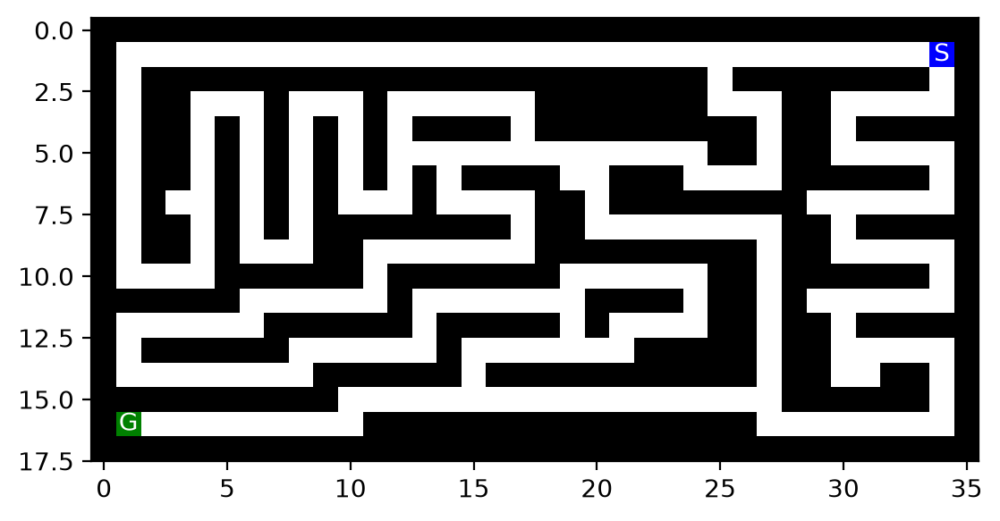

In [8]:
%run maze_helper.py
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np

#f = open("small_maze.txt", "r")
f = open("medium_maze.txt", "r")
#f = open("large_maze.txt", "r")    # this has only one solution!
#f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("loops_maze.txt", "r")
#f = open("L_maze.txt", "r")

maze_str = f.read()
maze = parse_maze(maze_str)

show_maze(maze)

My implementation follows the pseudo code from the slides/textbook.

In [9]:
# tree_search_solution.py has my actual implementation (not published)
import tree_search_solution as ts


# order in which we add new states to the frontier
ts.set_order("NESW")
#ts.set_order(random=True)

## Experiments - Uninformed Search

### BFS

In [10]:
result = ts.best_first_search(maze, strategy="BFS", animation=True)
print(result.keys())

dict_keys(['path', 'actions', 'nodes_expanded', 'max_depth', 'max_frontier', 'reached'])


In [11]:
print("Path:", result.get("path"))
print("Reached:", result.get("reached"))
print("Maze animation:", result.get("maze_anim"))

Path: [<tree_search_solution.Node object at 0x0000020AA497EC10>, <tree_search_solution.Node object at 0x0000020AA4A0D550>, <tree_search_solution.Node object at 0x0000020AA4A0F540>, <tree_search_solution.Node object at 0x0000020AA45E5CC0>, <tree_search_solution.Node object at 0x0000020AA45E5C50>, <tree_search_solution.Node object at 0x0000020AA45E5E80>, <tree_search_solution.Node object at 0x0000020AA45E5F60>, <tree_search_solution.Node object at 0x0000020AA45E6040>, <tree_search_solution.Node object at 0x0000020AA45E6120>, <tree_search_solution.Node object at 0x0000020AA45E6200>, <tree_search_solution.Node object at 0x0000020AA45E62E0>, <tree_search_solution.Node object at 0x0000020AA45E6430>, <tree_search_solution.Node object at 0x0000020AA45E6580>, <tree_search_solution.Node object at 0x0000020AA45E66D0>, <tree_search_solution.Node object at 0x0000020AA45E6820>, <tree_search_solution.Node object at 0x0000020AA45E6970>, <tree_search_solution.Node object at 0x0000020AA45E6AC0>, <tree_s

In [12]:
ts.show_path(maze, result)

Path length: 68
Nodes expanded: 269
Max depth: 68
Max frontier: 9


### DFS 

This implementation does not use a reached data structure and has space complexity $O(bm)$ instead of $O(b^m)$ when we reuse the tree search algorithm from BFS!

We need to check for all cycles. If we do not break all cycles correctly, then we can end up in an infinite loop.

In [16]:
ts.set_order("NESW")
result = ts.DFS(maze, max_tries=100000, animation=True)
print(result.keys())

dict_keys(['path', 'actions', 'nodes_expanded', 'max_depth', 'max_frontier', 'reached'])


In [17]:
frames = []
path = result.get("path")

if path is not None:
    for i in range(len(path) + 1):
        frame = maze.copy()
        for node in path[:i]:
            r, c = node.pos
            if frame[r, c] not in ("S", "G"):
                frame[r, c] = "."
        frames.append(frame)
else:
    frames.append(maze.copy())

result["maze_anim"] = frames
animate_maze(result)

Path length: 152
Reached squares: 161
Action sequence: ['W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'E', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'E', 'E', 'S', 'S', 'S', 'S', 'S', 'S', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'E', 'E', 'S', 'S', 'S', 'S', 'E', 'E', 'N', 'N', 'E', 'E', 'S', 'S', 'E', 'E', 'E', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'N', 'E', 'E', 'E', 'E', 'E', 'N', 'N', 'E', 'E', 'E', 'E', 'E', 'E', 'S', 'S', 'W', 'W', 'W', 'W', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W']


Note on the visualization: I use gray for areas that the algorithm has explored, but DFS has already removed it from memory so they are shown white.

The exploration order (order used in the expand function) is very important for DFS! DFS uses LIFO so the directions come from the stack in reverse order.

I set the exploration order so that South will be explored before West.

In [19]:
ts.set_order("ENWS")

%time result = ts.DFS(maze, max_tries=100000)

print(result.keys())

CPU times: total: 0 ns
Wall time: 728 μs
dict_keys(['path', 'actions', 'nodes_expanded', 'max_depth', 'max_frontier', 'reached'])


In [20]:
frames = []
path = result.get("path")

if path is not None:
    for i in range(len(path) + 1):
        frame = maze.copy()

        for node in path[:i]:
            r, c = node.pos

            if frame[r, c] not in ("S", "G"):
                frame[r, c] = "."

        frames.append(frame)
else:
    frames.append(maze.copy())

result["maze_anim"] = frames

animate_maze(result)

Path length: 152
Reached squares: 161
Action sequence: ['W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'E', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'E', 'E', 'S', 'S', 'S', 'S', 'S', 'S', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'E', 'E', 'S', 'S', 'S', 'S', 'E', 'E', 'N', 'N', 'E', 'E', 'S', 'S', 'E', 'E', 'E', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'N', 'E', 'E', 'E', 'E', 'E', 'N', 'N', 'E', 'E', 'E', 'E', 'E', 'E', 'S', 'S', 'W', 'W', 'W', 'W', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W']


The best exploration order depends on the Maze, so we probably should rather use random exploration. Here the order is randomized in at each step. It will produce sometimes give good and sometimes bad solutions and can be used with multi[ple restarts.

In [22]:
ts.set_order(random=True)

%time result = ts.DFS(maze, max_tries=100000)

print(result.keys())

CPU times: total: 0 ns
Wall time: 3.13 ms
dict_keys(['path', 'actions', 'nodes_expanded', 'max_depth', 'max_frontier', 'reached'])


In [23]:
frames = []
path = result.get("path")

if path is not None:
    for i in range(len(path) + 1):
        frame = maze.copy()

        for node in path[:i]:
            r, c = node.pos

            if frame[r, c] not in ("S", "G"):
                frame[r, c] = "."

        frames.append(frame)
else:
    frames.append(maze.copy())

result["maze_anim"] = frames

animate_maze(result)

Path length: 154
Reached squares: 265
Action sequence: ['S', 'S', 'W', 'W', 'W', 'W', 'S', 'S', 'E', 'E', 'E', 'E', 'S', 'S', 'W', 'W', 'W', 'W', 'S', 'S', 'E', 'E', 'E', 'E', 'S', 'S', 'W', 'W', 'W', 'W', 'S', 'S', 'E', 'E', 'E', 'E', 'S', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'N', 'N', 'W', 'N', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'E', 'E', 'E', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'N', 'E', 'E', 'E', 'E', 'E', 'N', 'N', 'E', 'E', 'E', 'E', 'E', 'E', 'N', 'E', 'E', 'E', 'E', 'E', 'S', 'S', 'W', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W']


## Experiments - Informed Search

### Greedy Best-First Search (GBFS)

Walks towards the goal using the heuristic. It is greedy and not guaranteed to find the optimal solution.

In [14]:
# set the heuristic to Manhattan distance
ts.heuristic = ts.manhattan

In [24]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "GBFS", animation = True)
animate_maze(result)

CPU times: total: 0 ns
Wall time: 539 μs
Path length: 74
Reached squares: 82
Action sequence: ['S', 'S', 'W', 'W', 'W', 'W', 'S', 'S', 'E', 'E', 'E', 'E', 'S', 'S', 'W', 'W', 'W', 'W', 'S', 'S', 'E', 'E', 'E', 'E', 'S', 'S', 'W', 'W', 'W', 'W', 'S', 'S', 'E', 'E', 'E', 'E', 'S', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'N', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W']


KeyError: 'maze_anim'

### A* Search

Uses an admissible heuristic and is guaranteed to find the optimal solution. It needs to explore a little more compared to GBFS. 

In [ ]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy="GBFS")

print(result.keys())

CPU times: total: 0 ns
Wall time: 967 μs
dict_keys(['path', 'actions', 'nodes_expanded', 'max_depth', 'max_frontier', 'reached'])


In [26]:
frames = []
path = result.get("path")

if path is not None:
    for i in range(len(path) + 1):
        frame = maze.copy()

        for node in path[:i]:
            r, c = node.pos

            if frame[r, c] not in ("S", "G"):
                frame[r, c] = "."

        frames.append(frame)
else:
    frames.append(maze.copy())

result["maze_anim"] = frames

animate_maze(result)

Path length: 152
Reached squares: 167
Action sequence: ['W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'E', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'E', 'E', 'S', 'S', 'S', 'S', 'S', 'S', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'E', 'E', 'S', 'S', 'S', 'S', 'E', 'E', 'N', 'N', 'E', 'E', 'S', 'S', 'E', 'E', 'E', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'N', 'E', 'E', 'E', 'E', 'E', 'N', 'N', 'E', 'E', 'E', 'E', 'E', 'E', 'S', 'S', 'W', 'W', 'W', 'W', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W']
